# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [2]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Data check & notes before plotting

The next cell defines **one shared style** (CVD-safe palette, title helper) used by every figure, and runs a quick sanity check on the data.

What the check shows and how it affects the charts:
- **234 rows, no missing values, no duplicated country codes** — no cleaning needed.
- The world total is **3.69 billion in 1970 → 7.97 billion in 2022**, which matches the "8 billion" in Q6.
- Some rows are **tiny territories** (Vatican City has 510 people, Tokelau 1,871). They are real data, not errors, and they create extreme values for density (Q4) and % change (Q5), so those charts use log scales / capped colour scales and name the extremes.
- The observation years are **unevenly spaced** (10-year steps to 2010, then 2015, 2020, 2022). Q1 uses a numeric time axis so the spacing stays honest; Q7 shows one bar per observed year.
- Continent coding follows the source: **Russia counts as Europe** (so Europe includes 17 M km² of Russian land), **Turkey as Asia**.


In [3]:
import plotly.graph_objects as go   # only used to add context layers / reference lines on top of px figures

# ── One palette for the whole notebook (CVD-safe: orange ↔ blue, never red ↔ green) ──
ACCENT  = '#E66100'   # orange → the group the question is about (Africa in Q1, Q2, Q7; "shrank" in Q5)
ACCENT2 = '#1F5FA8'   # blue   → second highlight (Europe in Q7, Asia in Q6, "grew" in Q5)
GREY    = '#BDBDBD'   # context
LIGHT   = '#E3E3E3'   # faint context (background dots)
DARK    = '#3A3A3A'   # text, reference lines
FONT    = dict(family='Arial, sans-serif', size=13, color=DARK)

def hl(text, colour):
    """Colour a word in a title so the title doubles as the legend."""
    return f"<span style='color:{colour}'><b>{text}</b></span>"

def title(main, sub):
    """Insight title + smaller grey subtitle that says what is plotted."""
    return dict(text=f"<b>{main}</b><br><span style='font-size:13px;color:#6E6E6E'>{sub}</span>",
                x=0.01, xanchor='left', y=0.97, yanchor='top', font=dict(size=18))

# ── Quick data check before plotting ──
print('Missing values:', df.isna().sum().sum(), '| duplicated country codes:', df['CCA3'].duplicated().sum())
print('\nCountries / territories per continent')
print(df['Continent'].value_counts().to_string())
print('\nWorld population by year (billions)')
print((df_long.groupby('Year')['Population'].sum() / 1e9).round(2).to_string())
print('\nSmallest entries (tiny territories are real rows, not errors):')
print(df.nsmallest(3, '2022 Population')[['Country', 'Continent', '2022 Population']].to_string(index=False))


Missing values: 0 | duplicated country codes: 0

Countries / territories per continent
Continent
Africa           57
Asia             50
Europe           50
North America    40
Oceania          23
South America    14

World population by year (billions)
Year
1970    3.69
1980    4.44
1990    5.31
2000    6.15
2010    6.98
2015    7.42
2020    7.84
2022    7.97

Smallest entries (tiny territories are real rows, not errors):
     Country Continent  2022 Population
Vatican City    Europe              510
     Tokelau   Oceania             1871
        Niue   Oceania             1934


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

**Chart: line chart, indexed to 1970 = 1×.**

**Why this chart:** the question is about change over time for six groups, and a line chart is the best way to show a trend and its pace (the slope). Indexing every continent to its *own* 1970 size puts continents of very different sizes on one comparable scale — plotting raw totals would only show that Asia is biggest, not who is growing fastest.

**Design choices**
- The y-axis is a growth multiple (1×, 2×, 3×, 4×), which answers "relative to its 1970 size" directly; a dotted line marks the 1970 size.
- **Africa — the answer — is the only coloured line** (orange, thicker); the other five continents are grey context.
- Direct labels at the end of each line (with the 2022 multiple) replace the legend.
- Markers show the real observation years on a numeric time axis, so the uneven spacing (10, 5 and 2 years) is not hidden. No vertical gridlines, only faint horizontal ones.

**What it shows:** Africa's population is **3.9× its 1970 size** (365 M → 1.43 B) and its line is still the steepest. Oceania (2.3×), South America (2.3×) and Asia (2.2×) form a middle group, North America reached 1.9×, and **Europe barely moved (1.1×)**.


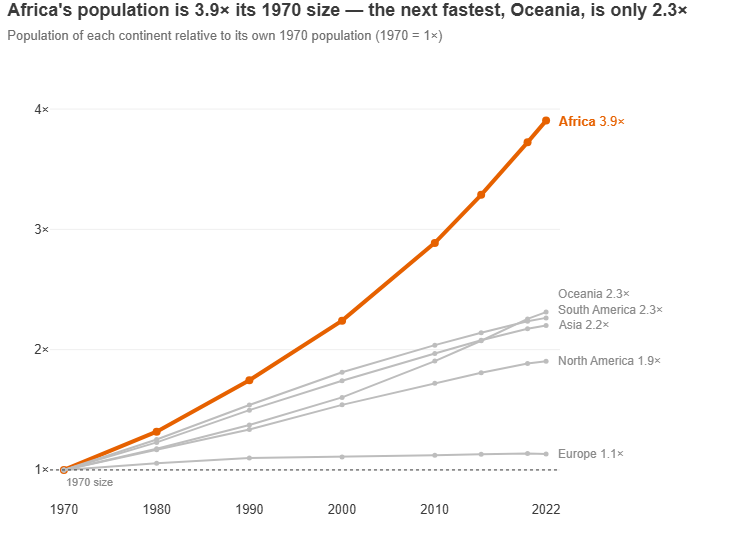

In [4]:
# Q1 — growth of each continent relative to its own 1970 size → LINE CHART (indexed, 1970 = 1×)
cont = df_long.groupby(['Continent', 'Year'], as_index=False)['Population'].sum()
base_1970 = cont.loc[cont['Year'] == 1970].set_index('Continent')['Population']
cont['Growth'] = cont['Population'] / cont['Continent'].map(base_1970)        # 1.0 = same size as in 1970

end = cont.loc[cont['Year'] == 2022].set_index('Continent')['Growth'].sort_values(ascending=False)
fastest, second, slowest = end.index[0], end.index[1], end.index[-1]
colours = {c: (ACCENT if c == fastest else GREY) for c in end.index}

fig = px.line(cont, x='Year', y='Growth', color='Continent', markers=True,
              color_discrete_map=colours, custom_data=['Continent', 'Population'],
              template='plotly_white',
              title=f"{fastest}'s population is {end[fastest]:.1f}× its 1970 size — "
                    f"the next fastest, {second}, is only {end[second]:.1f}×")

fig.update_traces(line=dict(width=2), marker=dict(size=5),
                  hovertemplate='<b>%{customdata[0]}</b>, %{x}<br>%{y:.2f}× its 1970 size'
                                '<br>%{customdata[1]:,.0f} people<extra></extra>')
fig.update_traces(selector=dict(name=fastest), line=dict(width=4), marker=dict(size=8))

# Direct labels at the end of each line instead of a legend (nudged apart where lines converge)
label_y, last = {}, -np.inf
for c, g in end.sort_values().items():
    label_y[c] = max(g, last + 0.13)
    last = label_y[c]
for c, g in end.items():
    fig.add_annotation(x=2022, y=label_y[c], text=f'<b>{c}</b> {g:.1f}×' if c == fastest else f'{c} {g:.1f}×',
                       xanchor='left', xshift=10, showarrow=False,
                       font=dict(color=ACCENT if c == fastest else '#8A8A8A', size=13 if c == fastest else 12))

fig.add_hline(y=1, line=dict(color=DARK, width=1, dash='dot'))
fig.add_annotation(x=1970, y=1, text='1970 size', yshift=-12, xanchor='left', showarrow=False,
                   font=dict(size=11, color='#8A8A8A'))

fig.update_layout(title=title(fig.layout.title.text,
                              'Population of each continent relative to its own 1970 population (1970 = 1×)'),
                  showlegend=False, font=FONT, height=540, margin=dict(l=50, r=170, t=85, b=40))
fig.update_xaxes(title=None, showgrid=False, tickvals=[1970, 1980, 1990, 2000, 2010, 2022], range=[1968.5, 2023.5])
fig.update_yaxes(title=None, tickvals=[1, 2, 3, 4], ticktext=['1×', '2×', '3×', '4×'], range=[0.75, 4.2],
                 gridcolor='#EFEFEF', zeroline=False)
fig.show()


---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

**Chart: sorted horizontal bar chart.**

**Why this chart:** the question ranks one number (people added) across 15 named countries. Bar length is the most precise way to compare magnitudes, sorting answers "which added the most" at a glance, and a horizontal layout keeps the country names readable.

**Design choices**
- Absolute change (2022 − 1970 population), sorted with the largest on top.
- **African countries in orange, all others grey**, so the "how many are in Africa" part can be counted instantly; the orange word *Africa* in the title works as the legend.
- Every bar carries its value label (+860 M …), so the x-axis and gridlines are removed.

**What it shows:** **4 of the 15 are African** — Nigeria (+163 M, 4th), Ethiopia (+95 M), DR Congo (+79 M) and Egypt (+76 M). Eight of the 15 are in Asia. **India (+860 M) and China (+603 M) together added 1.46 billion people — more than the other 13 countries combined (1.38 billion).**


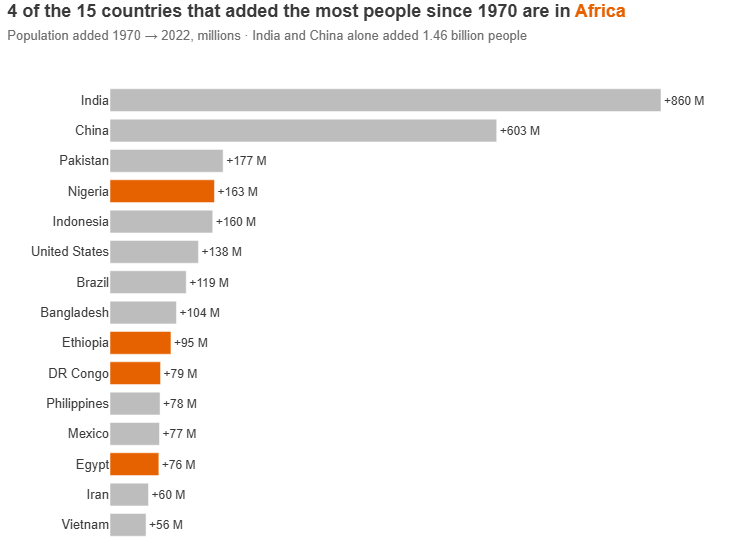

In [5]:
# Q2 — the 15 countries that added the most people, 1970 → 2022 → SORTED (horizontal) BAR CHART
top15 = (df.assign(Added=df['2022 Population'] - df['1970 Population'])
           .nlargest(15, 'Added')[['Country', 'Continent', 'Added']])
top15['Group'] = np.where(top15['Continent'] == 'Africa', 'Africa', 'Other continents')
top15['Label'] = (top15['Added'] / 1e6).map(lambda v: f'+{v:,.0f} M')

n_africa = (top15['Group'] == 'Africa').sum()
china_india = top15.loc[top15['Country'].isin(['India', 'China']), 'Added'].sum() / 1e9

fig = px.bar(top15, x='Added', y='Country', orientation='h', color='Group', text='Label',
             color_discrete_map={'Africa': ACCENT, 'Other continents': GREY},
             custom_data=['Continent'], template='plotly_white',
             title=f"{n_africa} of the 15 countries that added the most people since 1970 are in {hl('Africa', ACCENT)}")

fig.update_traces(textposition='outside', cliponaxis=False, textfont=dict(size=12),
                  hovertemplate='<b>%{y}</b> (%{customdata[0]})<br>+%{x:,.0f} people since 1970<extra></extra>')
fig.update_layout(title=title(fig.layout.title.text,
                              f'Population added 1970 → 2022, millions · India and China alone added '
                              f'{china_india:.2f} billion people'),
                  showlegend=False, font=FONT, height=560, bargap=0.25,
                  margin=dict(l=110, r=40, t=85, b=20))
fig.update_xaxes(visible=False)                                   # every bar is labelled → no axis needed
fig.update_yaxes(title=None, categoryorder='total ascending', ticks='', showgrid=False)  # largest on top
fig.show()


---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

**Chart: scatter plot on log–log scales, as small multiples (one panel per continent).**

**Why this chart:** the relationship between two numeric variables is exactly what a scatter plot shows. Both variables span many orders of magnitude (1 km² Vatican to 17 M km² Russia; 510 to 1.4 B people), so **log scales are required** — on linear axes almost every country collapses into one corner. Splitting into panels answers "does it differ by continent?" much more clearly than six overlapping colours in one plot.

**Design choices**
- Each panel highlights one continent in blue on top of **all other countries in light grey**, so every continent is judged against the same world context.
- The same dashed **world trend line** (log–log regression over all countries) appears in every panel as a common benchmark; dots above it hold more people than expected for their size, dots below hold fewer.
- Panel titles state the answer per continent: how many times the trend a *typical* (median) country sits. Panels are ordered from most above to most below the trend.
- The countries that clearly break the pattern are labelled directly; shared axes with plain-language ticks (10k, 1M km², 1B).

**What it shows:** yes — bigger countries clearly hold more people (**r = 0.87 on log scales**; 10× more land ≈ 5× more people). But continents differ: a typical **Asian** country has **2.2× the people** the trend predicts, Europe, Africa and North America sit right on it (~1.1×), while **South America (0.5×) and Oceania (0.4×)** are emptier than their size suggests. Far **above** the line: city-states (Macau, Singapore, Hong Kong, Monaco) and the giants Bangladesh and India; far **below**: Greenland, the Falkland Islands, Niue, Western Sahara, Iceland and Mongolia — ice, desert and steppe.


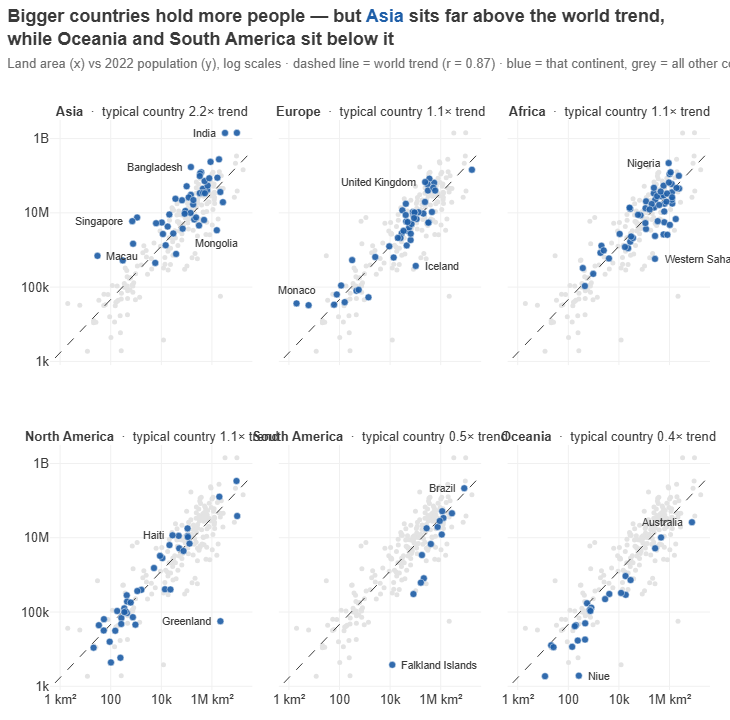

In [6]:
# Q3 — land area vs 2022 population → SCATTER PLOT (log–log), small multiples by continent
d3 = df[['Country', 'Continent', 'Area', '2022 Population']].copy()
lx, ly = np.log10(d3['Area']), np.log10(d3['2022 Population'])
slope, intercept = np.polyfit(lx, ly, 1)                          # world trend on log–log scales
r = np.corrcoef(lx, ly)[0, 1]
d3['vs_trend'] = 10 ** (ly - (intercept + slope * lx))           # 2 = twice the people expected for its size

typical = d3.groupby('Continent')['vs_trend'].median()          # typical (median) country per continent
order = typical.sort_values(ascending=False).index.tolist()

fig = px.scatter(d3, x='Area', y='2022 Population', facet_col='Continent', facet_col_wrap=3,
                 category_orders={'Continent': order}, log_x=True, log_y=True,
                 hover_name='Country', custom_data=['Continent', 'vs_trend'],
                 color_discrete_sequence=[ACCENT2], template='plotly_white',
                 facet_row_spacing=0.14, facet_col_spacing=0.04,
                 title=f"Bigger countries hold more people — but {hl('Asia', ACCENT2)} sits far above the world trend,"
                       f"<br>while Oceania and South America sit below it")
fig.update_traces(marker=dict(size=7, opacity=0.9, line=dict(color='white', width=0.5)),
                  hovertemplate='<b>%{hovertext}</b><br>%{x:,.0f} km² · %{y:,.0f} people'
                                '<br>%{customdata[1]:.2f}× the world trend<extra></extra>')

# Grey context (all countries) + dashed world trend in every panel, drawn underneath the highlighted dots
x_line = np.logspace(-0.2, 7.4, 40)
y_line = 10 ** (intercept + slope * np.log10(x_line))
panel = {}
for tr in list(fig.data):
    panel[tr.customdata[0][0]] = (tr.xaxis, tr.yaxis)
    fig.add_scatter(x=d3['Area'], y=d3['2022 Population'], mode='markers', xaxis=tr.xaxis, yaxis=tr.yaxis,
                    marker=dict(color=LIGHT, size=5), hoverinfo='skip', showlegend=False)
    fig.add_scatter(x=x_line, y=y_line, mode='lines', xaxis=tr.xaxis, yaxis=tr.yaxis,
                    line=dict(color=DARK, width=1, dash='dash'), hoverinfo='skip', showlegend=False)
k = len(panel)
fig.data = fig.data[k:] + fig.data[:k]                            # context first, highlights on top

# Panel titles carry the per-continent answer: how a typical country compares with the trend
fig.for_each_annotation(lambda a: a.update(
    text=f"<b>{a.text.split('=')[1]}</b>  ·  typical country {typical[a.text.split('=')[1]]:.1f}× trend",
    font=dict(size=13)))

# Label the countries that clearly break the pattern (text placed right / left / above / below the dot)
place = {'r': dict(xanchor='left', xshift=7), 'l': dict(xanchor='right', xshift=-7),
         'a': dict(yanchor='bottom', yshift=5), 'b': dict(yanchor='top', yshift=-5)}
outliers = {'Macau': 'r', 'Singapore': 'l', 'Bangladesh': 'l', 'India': 'l', 'Mongolia': 'b',
            'Monaco': 'a', 'United Kingdom': 'l', 'Iceland': 'r',
            'Nigeria': 'l', 'Western Sahara': 'r',
            'Haiti': 'l', 'Greenland': 'l',
            'Falkland Islands': 'r', 'Brazil': 'l',
            'Niue': 'r', 'Australia': 'l'}
for name, where in outliers.items():
    row = d3.loc[d3['Country'] == name].iloc[0]
    xa, ya = panel[row['Continent']]
    fig.add_annotation(x=np.log10(row['Area']), y=np.log10(row['2022 Population']),   # log axes → log10 coords
                       xref=xa, yref=ya, text=name, showarrow=False,
                       font=dict(size=10.5, color=DARK), **place[where])

ticks_x = dict(tickvals=[1, 1e2, 1e4, 1e6], ticktext=['1 km²', '100', '10k', '1M km²'])
ticks_y = dict(tickvals=[1e3, 1e5, 1e7, 1e9], ticktext=['1k', '100k', '10M', '1B'])
fig.update_xaxes(title=None, range=[-0.4, 7.6], gridcolor='#F0F0F0', zeroline=False, **ticks_x)
fig.update_yaxes(title=None, range=[2.9, 9.5], gridcolor='#F0F0F0', zeroline=False, **ticks_y)
fig.update_layout(title=title(fig.layout.title.text,
                              f'Land area (x) vs 2022 population (y), log scales · dashed line = world trend '
                              f'(r = {r:.2f}) · blue = that continent, grey = all other countries'),
                  showlegend=False, font=FONT, height=720, margin=dict(l=50, r=20, t=120, b=30))
fig.show()


---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

**Chart: box plot (log scale) with every country overlaid as a dot.**

**Why this chart:** the question asks for the *spread* within and across groups, not just the average. Box plots put the median, the middle 50 % and the outliers of several groups side by side. Overlaying the individual countries also shows how many there are per continent (South America has only 14). A violin plot would draw a smoothed shape from as few as 14 points and hide the individual extreme countries; a histogram cannot compare six groups compactly.

**Design choices**
- **Log scale**, because densities run from 0.03 (Greenland) to 23,172 people/km² (Macau). The box statistics are computed on log₁₀(density) so the whiskers are not distorted by the skew.
- Continents sorted by median; the **median and number of countries are written under each name** (direct labels instead of hover-only stats).
- A dotted line marks the **world median (95 people/km²)** as a reference; the extreme countries are named.
- One single colour: continent is already encoded by position on the x-axis, so a rainbow of box colours would be decoration only.

**What it shows:** the *typical* density differs by only ~12× between continents (median **18** in South America → **221** in North America), but the spread *inside* continents is enormous: **Asia ranges from 2 (Mongolia) to 23,172 (Macau)** and Europe from 3.6 (Iceland) to 18,234 (Monaco). North America's high median comes from its many small, crowded Caribbean islands; South America is the least dense and most uniform continent.


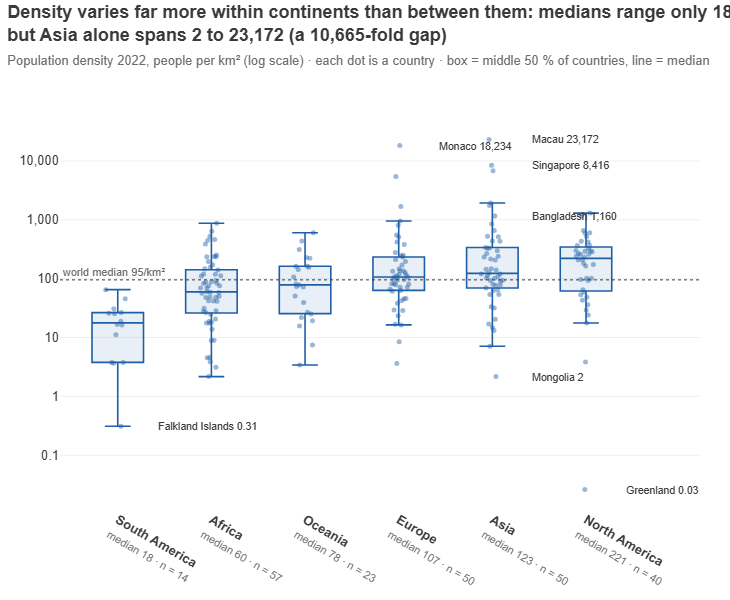

In [7]:
# Q4 — spread of population density within and across continents → BOX PLOT (log scale, every country shown)
d4 = df[['Country', 'Continent', 'Density']].copy()
d4['log_density'] = np.log10(d4['Density'])     # box statistics computed on the log scale (density is very skewed)

stats = d4.groupby('Continent')['Density'].agg(['median', 'min', 'max', 'count'])
order4 = stats['median'].sort_values().index.tolist()             # boxes sorted by median density
asia_min, asia_max = stats.loc['Asia', 'min'], stats.loc['Asia', 'max']
world_median = d4['Density'].median()

fig = px.box(d4, x='Continent', y='log_density', points='all', hover_name='Country',
             custom_data=['Density'], category_orders={'Continent': order4},
             color_discrete_sequence=[ACCENT2], template='plotly_white',
             title=f"Density varies far more within continents than between them: medians range only "
                   f"{stats['median'].min():.0f}–{stats['median'].max():.0f} people/km²,<br>but Asia alone spans "
                   f"{asia_min:.0f} to {asia_max:,.0f} (a {asia_max / asia_min:,.0f}-fold gap)")
fig.update_traces(jitter=0.5, pointpos=0, width=0.55, hoveron='points',
                  marker=dict(size=5, opacity=0.45, color=ACCENT2),
                  line=dict(width=1.6, color=ACCENT2), fillcolor='rgba(31,95,168,0.10)',
                  hovertemplate='<b>%{hovertext}</b><br>%{customdata[0]:,.1f} people/km²<extra></extra>')

# World median as a reference line
fig.add_hline(y=np.log10(world_median), line=dict(color=DARK, width=1, dash='dot'))
fig.add_annotation(x=0, xref='paper', y=np.log10(world_median), text=f'world median {world_median:.0f}/km²',
                   xanchor='left', yanchor='bottom', showarrow=False, font=dict(size=11, color='#6E6E6E'))

# Name the extremes so the reader knows what the far-out dots are
extremes = ['Macau', 'Monaco', 'Singapore', 'Bangladesh', 'Mongolia', 'Greenland', 'Falkland Islands']
for name in extremes:
    row = d4.loc[d4['Country'] == name].iloc[0]
    value = f"{row['Density']:.2f}" if row['Density'] < 1 else f"{row['Density']:,.0f}"
    fig.add_annotation(x=row['Continent'], y=row['log_density'], text=f'{name} {value}',
                       xanchor='left', xshift=38, showarrow=False, font=dict(size=10.5, color=DARK))

# Medians written under each continent name (direct labels instead of a hover-only statistic)
fig.update_xaxes(title=None, showgrid=False, tickvals=order4,
                 ticktext=[f"<b>{c}</b><br><span style='font-size:11px;color:#6E6E6E'>median "
                           f"{stats.loc[c, 'median']:.0f} · n = {stats.loc[c, 'count']}</span>" for c in order4])
fig.update_yaxes(title=None, tickvals=[-1, 0, 1, 2, 3, 4],                   # log10 values → real labels
                 ticktext=['0.1', '1', '10', '100', '1,000', '10,000'], gridcolor='#F0F0F0', zeroline=False)
fig.update_layout(title=title(fig.layout.title.text,
                              'Population density 2022, people per km² (log scale) · each dot is a country · '
                              'box = middle 50 % of countries, line = median'),
                  showlegend=False, font=FONT, height=600, margin=dict(l=60, r=30, t=120, b=60))
fig.show()


---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

**Chart: choropleth map with a diverging colour scale centred on 0 %.**

**Why this chart:** the question explicitly asks *where in the world* — location is part of the answer, so a map is the right form. The value is a signed percentage, so a diverging scale with its neutral point at 0 % separates "grew" from "shrank" immediately.

**Design choices**
- **Orange = shrank, blue = grew**, light grey ≈ no change — a colour-blind-safe pair (no red/green). The orange word *shrank* in the title doubles as the legend.
- The scale is capped at **−40 % and +120 %** so that a few extreme growers (Qatar +317 %) do not wash out the differences between everyone else. It is asymmetric on purpose: no country lost more than 39 %, while many grew by more than 100 %.
- Clean map: natural-earth projection, no frame or coastlines, Antarctica cropped, thin white borders.
- Many extremes are small islands that are invisible on a world map, so the **top-5 shrinkers and growers are listed directly under the map**.

**What it shows:** **34 of 234 countries/territories shrank, 18 of them in Europe** — a clear orange belt from the Baltics through Ukraine and Moldova to the Balkans (Lithuania −24 %, Latvia −23 %, Bosnia −23 %, Ukraine −19 %, Bulgaria −16 %), plus Japan (−2 %), Georgia and Armenia (−12 %), Puerto Rico and several small islands. **No African country shrank**; the typical African country grew by 78 %, and the deepest blues are in Sub-Saharan Africa (Niger +125 %, Angola +117 %) and the migration-driven Gulf states (Qatar +317 %, UAE +188 %).


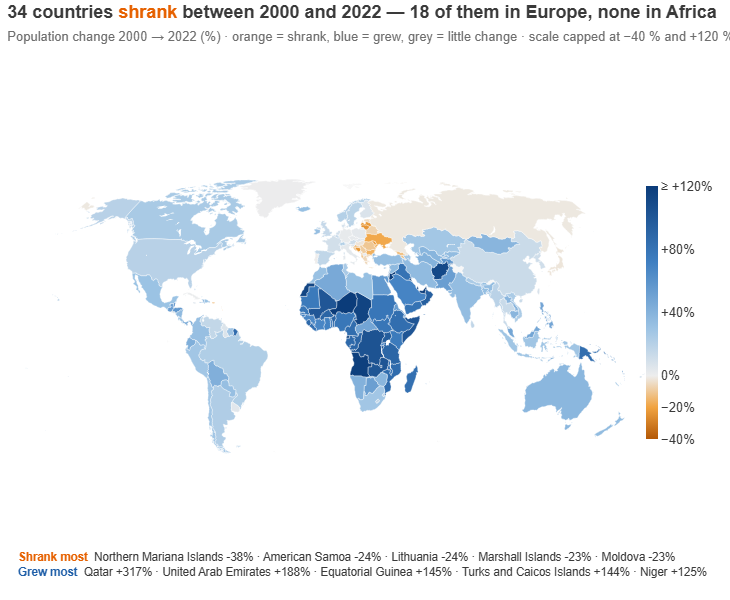

In [8]:
# Q5 — % population change 2000 → 2022 and where it happened → CHOROPLETH MAP (diverging scale centred on 0 %)
d5 = df[['CCA3', 'Country', 'Continent', '2000 Population', '2022 Population']].copy()
d5['Change'] = (d5['2022 Population'] / d5['2000 Population'] - 1) * 100
shrank = d5[d5['Change'] < 0]
n_shrank, n_eu = len(shrank), (shrank['Continent'] == 'Europe').sum()
n_africa_shrank = (shrank['Continent'] == 'Africa').sum()

# Diverging orange (shrank) ↔ blue (grew) scale, neutral grey exactly at 0 %.
# The range is capped at −40 % / +120 % so the few extreme growers (Qatar +317 %) don't wash out everyone else.
lo, hi = -40, 120
z = (0 - lo) / (hi - lo)                                         # position of 0 % on the 0–1 colour scale
scale = [[0, '#B35806'], [z * 0.5, '#F1A340'], [z, '#EDEDED'],
         [z + (1 - z) * 0.25, '#9CC3E4'], [z + (1 - z) * 0.6, '#3F7FC1'], [1, '#0B3C7A']]

fig = px.choropleth(d5, locations='CCA3', locationmode='ISO-3', color='Change', hover_name='Country',
                    custom_data=['Continent', '2000 Population', '2022 Population'],
                    color_continuous_scale=scale, range_color=[lo, hi], template='plotly_white',
                    title=f"{n_shrank} countries {hl('shrank', ACCENT)} between 2000 and 2022 — {n_eu} of them in "
                          f"Europe, {'none' if n_africa_shrank == 0 else n_africa_shrank} in Africa")
fig.update_traces(marker_line=dict(color='white', width=0.4),
                  hovertemplate='<b>%{hovertext}</b> (%{customdata[0]})<br>%{z:+.1f}% since 2000'
                                '<br>%{customdata[1]:,.0f} → %{customdata[2]:,.0f}<extra></extra>')
fig.update_geos(projection_type='natural earth', showframe=False, showcoastlines=False,
                showland=True, landcolor='#F7F7F7', showocean=False, lataxis_range=[-57, 84])

# Many extremes are islands too small to see on a map → list them directly
def fmt(t):
    return ' · '.join(f"{r.Country} {r.Change:+.0f}%" for r in t.itertuples())
fig.add_annotation(x=0.01, y=-0.02, xref='paper', yref='paper', xanchor='left', yanchor='top', align='left',
                   showarrow=False, font=dict(size=11.5, color=DARK),
                   text=f"{hl('Shrank most', ACCENT)}  {fmt(d5.nsmallest(5, 'Change'))}<br>"
                        f"{hl('Grew most', ACCENT2)}  {fmt(d5.nlargest(5, 'Change'))}")

fig.update_layout(title=title(fig.layout.title.text,
                              'Population change 2000 → 2022 (%) · orange = shrank, blue = grew, '
                              'grey = little change · scale capped at −40 % and +120 %'),
                  font=FONT, height=600, margin=dict(l=10, r=10, t=85, b=60),
                  coloraxis_colorbar=dict(title=None,
                                          tickvals=[-40, -20, 0, 40, 80, 120],
                                          ticktext=['−40%', '−20%', '0%', '+40%', '+80%', '≥ +120%'],
                                          thickness=12, len=0.6, x=0.98, outlinewidth=0))
fig.show()


---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

**Chart: treemap (World → continent → country).**

**Why this chart:** this is a part-to-whole question with two nested levels and 234 parts. A treemap shows both levels in one figure, with each tile's area proportional to its population. A pie or donut cannot hold 234 slices or show nesting, and a stacked bar would turn 234 segments into an unreadable strip.

**Design choices**
- Tile area = 2022 population; labels show each tile's **share of the world**.
- **Asia in blue** (the continent the title is about), all other continents grey: colour marks the finding rather than decorating every continent.
- Labels that would not fit a tile are hidden automatically (`uniformtext`); hover shows exact numbers and share of the continent, and clicking a continent zooms in.
- White borders separate the levels; the tiny Oceania tile is called out in the subtitle.

**What it shows:** **59 % of the world's 8.0 billion people live in Asia**, followed by Africa (18 %), Europe (9 %), North America (7.5 %), South America (5.5 %) and Oceania (0.6 %). **China (17.9 %) and India (17.8 %) together hold 36 %** — each of them has about as many people as the whole of Africa. Next come the United States (4.2 %), Indonesia (3.5 %) and Pakistan (3.0 %).


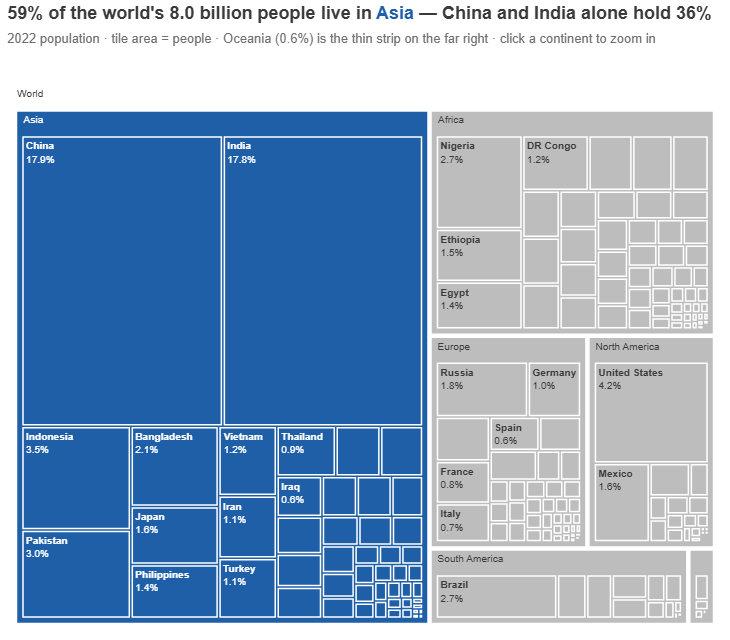

In [9]:
# Q6 — 2022 world population by continent and country (two levels, part-to-whole) → TREEMAP
d6 = df[['Continent', 'Country', '2022 Population']]
world_2022 = d6['2022 Population'].sum()
cont_share = d6.groupby('Continent')['2022 Population'].sum().sort_values(ascending=False) / world_2022
biggest = cont_share.index[0]
cn_in = d6.loc[d6['Country'].isin(['China', 'India']), '2022 Population'].sum() / world_2022

palette6 = {c: GREY for c in cont_share.index}
palette6[biggest] = ACCENT2                                      # accent only on the continent the title is about
palette6['(?)'] = 'white'                                        # the 'World' root tile

fig = px.treemap(d6, path=[px.Constant('World'), 'Continent', 'Country'], values='2022 Population',
                 color='Continent', color_discrete_map=palette6, template='plotly_white',
                 title=f"{cont_share[biggest]:.0%} of the world's {world_2022/1e9:.1f} billion people live in "
                       f"{hl(biggest, ACCENT2)} — China and India alone hold {cn_in:.0%}")

ids = fig.data[0].ids                                            # 'World', 'World/Asia', 'World/Asia/China', ...
depth = [i.count('/') for i in ids]
fig.update_traces(texttemplate=['' if d == 0 else '<b>%{label}</b>  %{percentRoot:.0%}' if d == 1
                                else '<b>%{label}</b><br>%{percentRoot:.1%}' for d in depth],
                  insidetextfont=dict(color=['white' if f'/{biggest}' in i else DARK for i in ids]),
                  hovertemplate='<b>%{label}</b><br>%{value:,.0f} people<br>%{percentRoot:.1%} of the world'
                                '<br>%{percentParent:.1%} of %{parent}<extra></extra>',
                  marker=dict(line=dict(color='white', width=1.5)), tiling=dict(pad=3),
                  root_color='white', pathbar_visible=False,
                  textfont=dict(size=13))
fig.update_layout(title=title(fig.layout.title.text,
                              f'2022 population · tile area = people · Oceania ({cont_share["Oceania"]:.1%}) is the thin strip '
                              f'on the far right · click a continent to zoom in'),
                  uniformtext=dict(minsize=10, mode='hide'),     # hide labels that would not fit their tile
                  font=FONT, height=640, margin=dict(l=10, r=10, t=85, b=10))
fig.show()


---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

**Chart: 100 % stacked bar chart.**

**Why this chart:** the question is about *shares of a whole* that always add up to 100 %, compared across years. A 100 % stacked bar shows the full composition in each year and how it shifts over time — something separate lines would not show, because they lose the "adds up to 100 %" whole.

**Design choices**
- Stack order is deliberate: **Africa sits on the 0 % baseline and Europe on the 100 % top edge**, so the two groups that change are read against straight, aligned edges.
- **Africa orange, Europe blue** (the two stories, same colours as earlier charts); Asia and Rest of the world in two greys as context.
- Percentages are written inside each segment, group names sit next to the last bar instead of a legend, and the y-axis is removed. One bar per observed year.
- A note marks the first observed year in which Africa's share exceeds Europe's.

**What it shows:** **Africa's share almost doubled (9.9 % → 17.9 %) while Europe's halved (17.8 % → 9.3 %)** — the two swapped places, with Africa overtaking Europe in the 1990s (by the 2000 observation). Asia's share stayed remarkably stable at 58–61 % (peaking in 2000 and slowly easing since), and the Rest of the world held ~14 %.


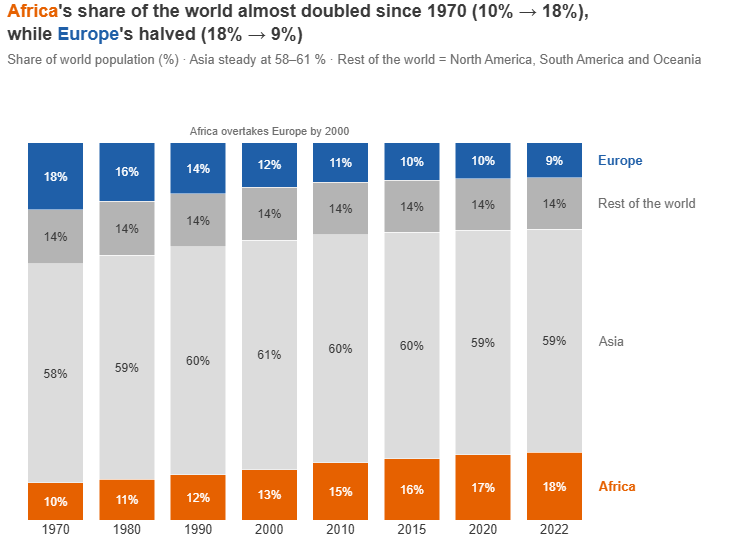

In [10]:
# Q7 — shares of world population over time (parts of a whole that always sum to 100 %) → 100 % STACKED BAR CHART
d7 = df_long.assign(Group=df_long['Continent'].where(df_long['Continent'].isin(['Africa', 'Asia', 'Europe']),
                                                     'Rest of the world'))
d7 = d7.groupby(['Year', 'Group'], as_index=False)['Population'].sum()
d7['Share'] = d7['Population'] / d7.groupby('Year')['Population'].transform('sum') * 100

s = d7.pivot(index='Year', columns='Group', values='Share')
overtake = s.index[(s['Africa'] > s['Europe'])].min()             # first year Africa's share beats Europe's
d7['Year'] = d7['Year'].astype(str)                               # one bar per observed year

order7 = ['Africa', 'Asia', 'Rest of the world', 'Europe']        # the two stories sit on the 0 % and 100 % edges
colours7 = {'Africa': ACCENT, 'Europe': ACCENT2, 'Asia': '#DCDCDC', 'Rest of the world': '#B4B4B4'}

fig = px.bar(d7, x='Year', y='Share', color='Group', category_orders={'Group': order7},
             color_discrete_map=colours7, custom_data=['Group', 'Population'], template='plotly_white',
             title=f"{hl('Africa', ACCENT)}'s share of the world almost doubled since 1970 "
                   f"({s.loc[1970, 'Africa']:.0f}% → {s.loc[2022, 'Africa']:.0f}%),<br>while "
                   f"{hl('Europe', ACCENT2)}'s halved ({s.loc[1970, 'Europe']:.0f}% → {s.loc[2022, 'Europe']:.0f}%)")
fig.update_traces(texttemplate='%{y:.0f}%', textposition='inside', insidetextanchor='middle',
                  textfont=dict(size=12, color=DARK),
                  hovertemplate='<b>%{customdata[0]}</b>, %{x}<br>%{y:.1f}% of world population'
                                '<br>%{customdata[1]:,.0f} people<extra></extra>')
fig.update_traces(selector=dict(name='Africa'), textfont_color='white')
fig.update_traces(selector=dict(name='Europe'), textfont_color='white')

# Direct labels to the right of the last bar instead of a legend
last = s.loc[2022, order7]
mid = last.cumsum() - last / 2
for g in order7:
    fig.add_annotation(x=1.0, xref='paper', y=mid[g], text=f'<b>{g}</b>' if g in ('Africa', 'Europe') else g,
                       xanchor='left', xshift=6, showarrow=False,
                       font=dict(size=13, color=colours7[g] if g in ('Africa', 'Europe') else '#6E6E6E'))
years = list(s.index)                                             # category axis → annotate by position index
fig.add_annotation(x=years.index(overtake), y=100, text=f'Africa overtakes Europe by {overtake}', yanchor='bottom',
                   yshift=4, showarrow=False, font=dict(size=11, color='#6E6E6E'))

fig.update_layout(title=title(fig.layout.title.text,
                              f'Share of world population (%) · Asia steady at {s["Asia"].min():.0f}–{s["Asia"].max():.0f} % · '
                              'Rest of the world = North America, South America and Oceania'),
                  barmode='stack', bargap=0.22, showlegend=False, font=FONT, height=560,
                  margin=dict(l=20, r=140, t=120, b=40))
fig.update_xaxes(title=None, showgrid=False, ticks='', type='category')   # years as categories
fig.update_yaxes(visible=False, range=[0, 106])                    # labels inside the bars carry the numbers
fig.show()


---
## Summary of findings

| Q | Question | Chart | Key finding |
|---|---|---|---|
| 1 | Which continent is growing fastest? | Line chart (indexed) | Africa is 3.9× its 1970 size; Europe only 1.1× |
| 2 | Which countries added the most people? | Sorted bar chart | 4 of the top 15 are African; India + China added more than the other 13 combined |
| 3 | Do bigger countries have more people? | Scatter plot (log–log, small multiples) | Yes (r = 0.87), but Asia sits 2.2× above the trend, Oceania and South America below it |
| 4 | How crowded are the continents? | Box plot (log scale) | Medians differ ~12×, but Asia alone spans a 10,000-fold range |
| 5 | Where did populations grow / shrink? | Choropleth map (diverging) | 34 shrank, 18 of them in Europe; none in Africa |
| 6 | Where do the 8 billion live? | Treemap | 59 % in Asia; China and India hold 36 % between them |
| 7 | Whose share is rising? | 100 % stacked bar chart | Africa's share almost doubled, Europe's halved — they swapped places in the 1990s |

**The overall story:** the world's population centre of gravity has always been Asia, but the *growth* has shifted to Africa, while Europe has stalled and parts of Eastern Europe are shrinking.

Seven different chart types are used — one per question. Histogram, violin plot and bubble chart were not needed: no question asks for the distribution of a single variable on its own (histogram), the density spread is better served by a box plot with the individual countries visible (violin), and no question involves a third numeric variable that would justify bubble size.
